# 03. DistilBERT: дообучение трансформера для классификации документов

## Что такое DistilBERT

**DistilBERT** --- нейросеть, которую уже обучили на огромном объёме английского текста (Википедия и книги, миллиарды слов).
Задачей было угадывать пропущенные слова в предложениях. Так модель выучила язык: какие слова похожи по смыслу,
как строятся фразы, что значит слово в контексте.

Определять тип документа она сама по себе не умеет, но она уже **понимает язык** --- и это главное.

## Дообучение (fine-tuning)

Берём готовую модель и **доучиваем на нашей задаче**:
1. к модели добавляется маленький **классификатор на 6 классов** --- новый слой со случайными весами;
2. модель смотрит на наши 9 600 фрагментов с правильными ответами и подстраивает веса (в основном нового слоя, немного свои);
3. за несколько проходов по данным модель учится определять тип документа.

Это как взять человека, который хорошо знает английский, и за пару часов научить отличать договоры от новостей.

| | TF-IDF + логистическая регрессия | DistilBERT |
|---|---|---|
| Что знает заранее | ничего, только наши тексты | язык целиком |
| Порядок слов | не учитывает | учитывает |
| Новые слова и синонимы | не понимает | понимает похожие по смыслу |
| Размер модели | ~3 МБ | ~250 МБ |
| Скорость | мгновенно | медленнее, для обучения нужна видеокарта |

## Токенизация

Нейросеть работает не со словами, а с **токенами** --- кусочками слов. Частые слова --- один токен (`the`, `loan`),
редкие режутся на части (`repayment` → `repay` + `##ment`). Поэтому незнакомых слов для модели не бывает:
она собирает их из кусочков.

Лимит DistilBERT --- **512 токенов** за раз. Наши фрагменты по 60--120 слов --- примерно 80--160 токенов, помещаются с запасом.

## 1. Загрузка токенизатора

- `AutoTokenizer` сам подбирает нужный токенизатор по имени модели;
- `from_pretrained(...)` скачивает его с Hugging Face (как `load_dataset`, только для моделей) в кэш `D:\cache\huggingface`;
- `distilbert-base-uncased` --- имя модели. `uncased` значит, что регистр не важен: `Loan` и `loan` для неё одно и то же.

In [1]:
from transformers import AutoTokenizer

tokenizer = AutoTokenizer.from_pretrained("distilbert-base-uncased")

## 2. Как текст режется на токены

`tokenizer.tokenize(текст)` показывает токены **словами** --- для нас, чтобы посмотреть, как режется текст.

In [2]:
a = tokenizer.tokenize("The Borrower shall repay the loan in full on the maturity date.")
print(a)

['the', 'borrow', '##er', 'shall', 'repay', 'the', 'loan', 'in', 'full', 'on', 'the', 'maturity', 'date', '.']


In [3]:
tokenizer.tokenize("Unbelievably, the cryptocurrency repayment was postponed.")

['un',
 '##bel',
 '##ie',
 '##va',
 '##bly',
 ',',
 'the',
 'crypt',
 '##oc',
 '##ur',
 '##ren',
 '##cy',
 'repay',
 '##ment',
 'was',
 'postponed',
 '.']

**Что видно:**
- всё стало **строчными буквами**: `The` → `the` (это и есть `uncased`);
- `Borrower` → **`borrow` + `##er`**: целиком слова «borrower» в словаре нет, а «borrow» и окончание «er» есть;
- **`##`** означает «продолжение предыдущего слова, без пробела»: так модель понимает, что `borrow` и `##er` --- одно слово;
- точка и запятая --- **отдельные токены**;
- редкое `Unbelievably` раскрошилось на 5 кусочков, `cryptocurrency` --- тоже на 5;
- `repayment` → `repay` + `##ment` --- корень и суффикс;
- частое `postponed` осталось целым.

**Вывод:** незнакомых слов для модели не бывает --- она соберёт их из кусочков.
TF-IDF так не умеет: слово, которого не было в обучающих текстах, он просто игнорирует.

## 3. Как токенизатор готовит текст для модели

`tokenize` показывает токены словами, но модель слов не понимает --- ей нужны **числа**.
Для этого токенизатор вызывают **напрямую**, как функцию: `tokenizer(текст)`. Он возвращает словарь:

| Ключ | Что это |
|---|---|
| `input_ids` | номера токенов в словаре модели. У каждого токена свой номер, например `the` = 1996. Словарь DistilBERT --- около 30 000 токенов |
| `attention_mask` | единицы и нули: какие токены настоящие, а какие пустые заглушки (подробно --- в разделе 5) |
| `token_type_ids` | к какому тексту относится токен: первому (0) или второму (1), если текстов два. У нас текст всегда один, а DistilBERT этот ключ не использует --- можно не обращать внимания |

Номеров в `input_ids` получается **на 2 больше**, чем токенов в `tokenize` для **того же** текста
(например, 16 вместо 14 для полного текста про Borrower). Эти два токена токенизатор добавляет сам --- см. ниже.

In [4]:
encoded = tokenizer("The Borrower shall repay the loan.")
print(encoded)

{'input_ids': [101, 1996, 17781, 2121, 4618, 24565, 1996, 5414, 1012, 102], 'token_type_ids': [0, 0, 0, 0, 0, 0, 0, 0, 0, 0], 'attention_mask': [1, 1, 1, 1, 1, 1, 1, 1, 1, 1]}


In [5]:
tokenizer.convert_ids_to_tokens(encoded["input_ids"])

['[CLS]',
 'the',
 'borrow',
 '##er',
 'shall',
 'repay',
 'the',
 'loan',
 '.',
 '[SEP]']

## 4. Специальные токены `[CLS]` и `[SEP]`

`convert_ids_to_tokens` превращает номера обратно в токены --- видно, что добавилось:

| Номер | 101 | 1996 | 17781 | 2121 | 4618 | 24565 | 1996 | 5414 | 1012 | 102 |
|---|---|---|---|---|---|---|---|---|---|---|
| Токен | **[CLS]** | the | borrow | ##er | shall | repay | the | loan | . | **[SEP]** |

- **`[CLS]`** (номер 101, от *classification*) --- всегда **в начале**. Пока модель читает текст, она собирает в этом токене
  смысл **всего текста целиком**. Потом именно по `[CLS]` классификатор решает, Legal это или News. Это «итог текста».
- **`[SEP]`** (номер 102, от *separator*) --- **в конце**, означает «текст закончился». Ещё он разделяет два текста,
  если их подают вместе (например, вопрос и ответ).

Токенизатор добавляет их **сам**: модель так обучена и ждёт их.

## 5. Пачки текстов: дополнение (padding) и обрезка (truncation)

Модель обрабатывает тексты **пачками** (батчами), например по 16 штук сразу --- так быстрее, особенно на видеокарте.
Пачка --- это **таблица**, и все строки в ней должны быть **одной длины**. А тексты разные.

Параметры токенизатора:
- **`padding=True`** --- **дополнить** короткие тексты заглушкой `[PAD]` до длины **самого длинного текста в пачке**;
- **`truncation=True`** + **`max_length=16`** --- **обрезать** всё, что длиннее 16 токенов (`[SEP]` всё равно ставится в конец).

У DistilBERT жёсткий предел --- 512 токенов, поэтому обрезка нужна всегда, а длинные документы будем резать на фрагменты.

In [6]:
tokenizer(
    ["Short text.", "This one is a bit longer than the first text."],
    padding=True,
    truncation=True,
    max_length=16,
)

{'input_ids': [[101, 2460, 3793, 1012, 102, 0, 0, 0, 0, 0, 0, 0, 0], [101, 2023, 2028, 2003, 1037, 2978, 2936, 2084, 1996, 2034, 3793, 1012, 102]], 'token_type_ids': [[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0], [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]], 'attention_mask': [[1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0], [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]]}

**Что получилось:**

```
Текст 1: [CLS] short text . [SEP] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD]
номера:   101  2460 3793 1012 102   0     0     0     0     0     0     0     0
маска:     1    1    1    1    1    0     0     0     0     0     0     0     0

Текст 2: [CLS] this one is a bit longer than the first text . [SEP]
номера:   101  2023 2028 2003 1037 2978 2936 2084 1996 2034 3793 1012 102
маска:     1    1    1    1    1    1    1    1    1    1    1    1    1
```

- Оба текста стали длиной **13**: короткий дотянули восемью `[PAD]` (номер **0**).
- Почему 13, а не 16? `padding=True` дополняет **до самого длинного текста в пачке**, а самый длинный --- 13.
  `max_length` работает только для **обрезки**. Чтобы дополнять ровно до 16, пишут `padding="max_length"`.

### attention_mask --- маска внимания

Внутри трансформера работает механизм **внимания** (attention): каждый токен «смотрит» на другие токены текста,
чтобы понять свой смысл в контексте. Например, `bank` рядом с `loan` --- это банк, а рядом с `river` --- берег.

Но `[PAD]` --- пустышки без смысла. Если модель будет на них смотреть, они испортят результат,
а их число зависит лишь от того, с какими соседями текст попал в пачку.

`attention_mask` говорит модели, на что смотреть:
- **1** --- настоящий токен, смотреть;
- **0** --- заглушка `[PAD]`, игнорировать.

Благодаря маске текст получает **один и тот же результат**, в какой бы пачке он ни оказался.

### Итог

| Что | Номер | Зачем |
|---|---|---|
| `[CLS]` | 101 | начало текста; по нему модель решает, какой класс |
| `[SEP]` | 102 | конец текста |
| `[PAD]` | 0 | заглушка, чтобы тексты в пачке были одной длины |
| `attention_mask` | 1 / 0 | 1 --- смотреть на токен, 0 --- игнорировать заглушку |

## 6. Подготовка данных для обучения

Обучаем на **том же** датасете, что и baseline, и проверяем на **том же** тесте --- иначе сравнение моделей будет нечестным.
Порядок: загрузить данные → разделить на три части → перевести названия классов в номера → собрать датасеты Hugging Face.

### Загрузка

Так же, как в baseline: `pd.read_parquet` читает готовый датасет (12 000 фрагментов, колонки `text`, `label`, `source`, `doc_id`).

Если под ячейкой появится красный текст `Exception ignored ... could not import module "pandas"` --- это не ошибка,
а безвредное предупреждение (слово *ignored* значит «проигнорировано»). Бывает в новых версиях Python, когда библиотека
transformers при загрузке проверяет, установлены ли другие библиотеки. Данные при этом загружаются нормально.

In [7]:
import pandas as pd

df = pd.read_parquet("../../data/processed/dataset.parquet")

### Разделение на три части: train, validation, test

**Первое разделение --- точно как в baseline** (`test_size=0.2`, `random_state=42`, `stratify`).
Благодаря `random_state=42` тест получается **побайтово тем же**: DistilBERT и baseline проверяются на одних и тех же 2400 текстах.

**Второе разделение --- validation (проверочная выборка).** Трансформер при слишком долгом обучении начинает **запоминать**
обучающие тексты, и качество на новых падает (переобучение). Поэтому во время обучения качество периодически проверяют
на текстах, которых модель не видела. Тест для этого брать **нельзя** --- он только для финальной оценки.
Поэтому из train отрезаем ещё 10%.

| Часть | Сколько | Для чего |
|---|---|---|
| **train** | 8 640 (90% от 9 600) | модель учится |
| **validation** | 960 (10% от 9 600) | проверяем качество **во время** обучения |
| **test** | 2 400 | финальная оценка, **тот же**, что у baseline |

Во втором `train_test_split` на вход идут уже `X_train` и `y_train`, а `stratify=y_train` сохраняет доли классов.
Старые `X_train`, `y_train` перезаписываются новыми, поменьше --- это нормально.

In [8]:
from sklearn.model_selection import train_test_split

X_train,X_test,y_train,y_test = train_test_split(
df["text"],
df["label"],
test_size=0.2,
random_state=42,
stratify=df["label"],
)



X_train,X_val,y_train,y_val = train_test_split(
X_train,
y_train,
test_size=0.1,
random_state=42,
stratify=y_train
)

print(f"Train_x:{len(X_train)},Test_x:{len(X_test)},Val_x:{len(X_val)}")
print(f"Train_y:{len(y_train)},Test_y:{len(y_test)},Val_y:{len(y_val)}")

Train_x:8640,Test_x:2400,Val_x:960
Train_y:8640,Test_y:2400,Val_y:960


### Названия классов → номера

Последний слой модели выдаёт **6 чисел** --- по одному на класс, с номерами 0--5. Поэтому правильный ответ
модель должна получать тоже **номером**, а не словом «Legal».

**Кто решает, какой номер у класса?** Мы сами --- модели всё равно. Важно, чтобы соответствие было **одинаковым везде**:
при обучении, при оценке и в приложении. Иначе модель скажет «2», а мы прочитаем это как другой класс.

Поэтому соответствие **строим из данных**, а не пишем вручную (нет опечаток, порядок гарантирован):
- `df["label"].unique()` --- каждое название класса один раз;
- `sorted(...)` --- по алфавиту, обычный список. Порядок совпадает с `model.classes_` в baseline:
  номер 2 --- Legal и там, и там. `unique()` без сортировки дал бы порядок первого появления в данных --- он может меняться.

In [9]:
labels = sorted(df["label"].unique())
print(labels)

['Financial', 'General', 'Legal', 'News', 'Scientific', 'Technical']


**`label2id`** --- словарь «название → номер». Им переводим ответы для обучения.

- `enumerate(labels)` даёт пары «номер, элемент»: `(0, 'Financial')`, `(1, 'General')`, ...
- `{label: i for i, label in enumerate(labels)}` --- **словарь в одну строку** (dict comprehension):
  «для каждой пары (номер, название) положи в словарь ключ --- название, значение --- номер».

In [10]:
label2id = {label: i for i,label in enumerate(labels)}
print(label2id)

{'Financial': 0, 'General': 1, 'Legal': 2, 'News': 3, 'Scientific': 4, 'Technical': 5}


**`id2label`** --- наоборот, «номер → название». Ключ и значение просто меняются местами: `{i: label ...}`.
По нему модель сможет вернуть ответ словом. Оба словаря потом сохранятся вместе с моделью в её настройках.

In [11]:
id2label = {i:label for i,label in enumerate(labels)}
print(id2label)

{0: 'Financial', 1: 'General', 2: 'Legal', 3: 'News', 4: 'Scientific', 5: 'Technical'}


### Датасеты в формате Hugging Face

**Зачем другой формат.** Анализ и подготовку удобно делать в pandas (DataFrame), а обучать будем через **`Trainer`**
из transformers. Он работает с `Dataset` из библиотеки `datasets`. Поэтому прямо перед обучением данные перекладываются
в этот формат. Плюс у него есть быстрый `.map()` --- им дальше токенизируем все тексты сразу.

**`Dataset.from_dict({...})`** --- словарь, где **ключ --- название колонки, значение --- список значений**:
- `"text"` --- тексты. `X_train` --- это Series из pandas, а нужен обычный список: `.tolist()`;
- `"label"` --- номер класса **для каждого текста** (не 6 номеров на весь датасет, а 8640 --- по одному на текст).
  Берём из `y_train` и переводим через `label2id`: `[label2id[name] for name in names]`.

**Вариант 1 (закомментирован)** --- три почти одинаковых куска кода. При копировании легко перепутать:
однажды метки validation и test оказались поменяны местами. При совпадении длин ошибки не было бы вовсе ---
модель училась бы на неправильных ответах, и найти это было бы очень трудно.

**Вариант 2 --- функция `make_datasets(text, names)`.** Код написан один раз, а вызывается три раза с разными данными:
- `text` и `names` --- **параметры**, «пустые места» под данные;
- при вызове `make_datasets(X_val, y_val)` на их место встают `X_val` и `y_val`;
- тексты и метки передаются **парой** в одном вызове --- перепутать их почти невозможно;
- внутри функции используются только параметры, а не `X_train` --- поэтому она работает для любой части данных.

In [12]:
from datasets import Dataset

# label_train = [label2id[name] for name in y_train]
# label_test = [label2id[name] for name in y_test]
# label_val = [label2id[name] for name in y_val]




# train_ds = Dataset.from_dict({
#     "text" : X_train.tolist(),
#     "label" : label_train
# })

# val_ds = Dataset.from_dict({
#     "text" : X_val.tolist(),
#     "label" : label_val
# })

# test_ds = Dataset.from_dict({
#     "text" : X_test.tolist(),
#     "label" : label_test
# })



##### Через функцию тоже самое (красивее)

def make_datasets(text,names):
    return Dataset.from_dict({
        "text" : text.tolist(),
        "label" : [label2id[name] for name in names]
    })


train_ds = make_datasets(X_train,y_train)
val_ds = make_datasets(X_val,y_val)
test_ds = make_datasets(X_test,y_test)

**Проверка:** 8640 / 960 / 2400 строк, колонки `text` и `label`. Метка --- число от 0 до 5.
Можно сверить: `id2label[train_ds[0]["label"]]` должно совпадать с `y_train.iloc[0]`.

In [13]:
print(train_ds)
print(val_ds)
print(test_ds)

Dataset({
    features: ['text', 'label'],
    num_rows: 8640
})
Dataset({
    features: ['text', 'label'],
    num_rows: 960
})
Dataset({
    features: ['text', 'label'],
    num_rows: 2400
})


## 7. Токенизация всего датасета

Один текст мы уже токенизировали. Теперь --- все 12 000, и не по одному, а **пачками** (в десятки раз быстрее).

### Метод `.map()`

`.map(функция, batched=True)` применяет функцию ко всему датасету и **добавляет** её результат новыми колонками.
- **`batched=True`** --- функция получает не один текст, а **пачку** (по умолчанию 1000 штук);
- **`batch`** --- словарь, где по каждому ключу лежит **список** значений пачки: `batch["text"]` --- 1000 текстов;
- функция возвращает **словарь** «название колонки → список значений». Токенизатор как раз возвращает такой словарь
  (`input_ids`, `attention_mask`, `token_type_ids`) и умеет обрабатывать список текстов сразу.

### Параметры токенизатора

- **`truncation=True`, `max_length=256`** --- обрезать тексты длиннее 256 токенов. Наши фрагменты по 60--120 слов ---
  это 65--190 токенов, так что 256 хватает с запасом: обрезается всего 32 текста из 12 000 (в основном фрагменты
  с большим количеством цифр или кода --- они дробятся на много токенов).
- **Без `padding`!** Если дополнять здесь, каждый текст дотянется до самого длинного в пачке из 1000 --- будет много лишних `[PAD]`.
  Дополнять будем позже, при обучении, внутри маленьких пачек по 16 текстов (**динамическое дополнение**,
  `DataCollatorWithPadding`) --- там `[PAD]` гораздо меньше.

**Ловушка:** опечатка в имени параметра (`max_lenght`) **не вызывает ошибку** --- токенизатор молча игнорирует незнакомый
параметр, и обрезка идёт по максимуму модели (512). Код работает, но не так, как задумано.

In [14]:
def tokenize(batch):
    token_result = tokenizer(
    batch["text"],
    truncation = True,
    max_length = 256
    )
    return token_result


train_ds = train_ds.map(tokenize,batched = True)
val_ds = val_ds.map(tokenize,batched = True)
test_ds = test_ds.map(tokenize,batched = True)

Map:   0%|          | 0/8640 [00:00<?, ? examples/s]

Map:   0%|          | 0/960 [00:00<?, ? examples/s]

Map:   0%|          | 0/2400 [00:00<?, ? examples/s]

In [15]:
train_ds

Dataset({
    features: ['text', 'label', 'input_ids', 'token_type_ids', 'attention_mask'],
    num_rows: 8640
})

**Проверка длины в токенах.** `train_ds["input_ids"]` --- колонка целиком, список из 8640 списков.
`len(train_ds["input_ids"])` --- это **число текстов**, а не токенов. Длину **каждого** текста считаем так:
`[len(ids) for ids in train_ds["input_ids"]]`, а потом смотрим `min` и `max`.

Колонка `token_type_ids` тоже появилась --- токенизатор всегда её возвращает, DistilBERT её просто не использует.

In [16]:
lengths = [len(ids) for ids in train_ds["input_ids"]]
print(max(lengths),min(lengths))

256 65


## 8. Загрузка модели

**`AutoModelForSequenceClassification`** --- модель для классификации текстов. Это не «готовый классификатор документов»,
а **заготовка**: предобученный DistilBERT плюс **новый пустой слой-классификатор** на нужное число классов.

```
текст → [ DistilBERT ] → итог текста [CLS] → [ классификатор ] → 6 оценок → класс
           ГОТОВЫЙ                              НОВЫЙ, ПУСТОЙ
```

| Часть | Состояние |
|---|---|
| **DistilBERT** (~66 млн весов) | скачан предобученным, **понимает английский** |
| **Классификатор** (~595 тыс. весов: слой `pre_classifier` 768 × 768 и слой `classifier` 768 × 6) | создан только что, **веса случайные** |

Предобученный DistilBERT учили угадывать пропущенные слова, а не определять тип документа --- про наши классы он
ничего не знает. Поэтому веса классификатора взять неоткуда, они создаются случайными. Без обучения модель отвечает
**наугад** (около 1/6 = 17% верных). Обучение учит этот слой и немного подстраивает DistilBERT под наши тексты.

Параметры:

| Параметр | Что это |
|---|---|
| `"distilbert-base-uncased"` | та же модель, что у токенизатора --- они обязаны совпадать: модель понимает номера токенов только своего токенизатора |
| `num_labels=len(labels)` | сколько классов. Число **посчитано** из списка, а не вписано вручную --- если классов станет больше, код не надо менять |
| `id2label`, `label2id` | наши словари. Модель запишет их в свои настройки и сможет отвечать словами, а не номерами |

**При загрузке** скачивается около 250 МБ (в кэш `D:\cache\huggingface`; при повторном запуске модель берётся с диска
за секунду), а потом появляется отчёт о загрузке (`LOAD REPORT`):
- **MISSING** (`pre_classifier.*`, `classifier.*`) --- этих весов не было в предобученной модели, они **созданы заново**
  (случайные). Это и есть наш новый классификатор --- его нужно обучить;
- **UNEXPECTED** (`vocab_transform.*`, `vocab_projector.*`, `vocab_layer_norm.*`) --- веса из предобученной модели,
  которые **не нужны**: это была «голова» для угадывания пропущенных слов. Для классификации она не используется и отбрасывается.

**Это нормально:** модель сообщает, что классификатор новый и его нужно обучить --- ровно это мы и сделаем.
Строка `NOTE: Redirects are currently not supported in Windows` --- служебное сообщение PyTorch, ни на что не влияет.

In [17]:
from transformers import AutoModelForSequenceClassification

model = AutoModelForSequenceClassification.from_pretrained(
    "distilbert-base-uncased",
    num_labels= len(labels),
    id2label= id2label,
    label2id= label2id,
)

W1116 18:37:39.421000 25716 Lib\site-packages\torch\distributed\elastic\multiprocessing\redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
pre_classifier.weight   | MISSING    | 
classifier.bias         | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifier.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


**Проверка модели.**
- `model.config.id2label` --- модель запомнила наши 6 классов.
- **Число параметров (весов)** --- все числа внутри нейросети, которые меняются при обучении. Они хранятся во многих таблицах
  (по несколько на каждый слой; например, у классификатора --- таблица 6 × 768 и 6 сдвигов):
  - `model.parameters()` --- перебирает **все таблицы весов**;
  - `p.numel()` --- сколько чисел в **одной** таблице (размеры, перемноженные между собой: 6 × 768 = 4608);
  - `sum([p.numel() for p in model.parameters()])` --- для каждой таблицы взять число элементов и всё сложить.

  Ожидаем около **67 миллионов**. Для сравнения: у baseline 6 × 42 187 ≈ 253 тысячи весов --- в 260 раз меньше.

Две строки в одной ячейке: ноутбук сам показывает результат только **последней** строки, поэтому обе обёрнуты в `print`.

In [18]:
print(model.config.id2label)

print(sum([p.numel() for p in model.parameters()]))

{0: 'Financial', 1: 'General', 2: 'Legal', 3: 'News', 4: 'Scientific', 5: 'Technical'}
66958086


## 9. Функция метрик

**Зачем.** После каждой эпохи `Trainer` проверяет модель на validation. Сам он считает только **loss** (насколько модель
ошибается в вероятностях: чем меньше, тем лучше). Нам привычнее accuracy и macro-F1, как в baseline, --- поэтому даём
`Trainer` свою функцию. Он сам вызывает её после каждой проверки и печатает результат.

**Что функция получает --- `eval_pred`.** Это имя параметра (его выбираем сами). `Trainer` передаёт туда объект
`EvalPrediction`, внутри две вещи:

| Что | Где | Что это |
|---|---|---|
| предсказания модели | `eval_pred.predictions` | **logits** --- таблица 960 × 6: оценки по каждому классу для каждого текста |
| правильные ответы | `eval_pred.label_ids` | номера классов для 960 текстов |

`EvalPrediction` ведёт себя как **пара**, поэтому её можно сразу **распаковать**: `logits, labels = eval_pred`
(как `a, b = (10, 20)` → `a = 10`, `b = 20`). Распаковка работает и с обычной парой --- это удобно для проверки.

**Что такое logits.** Это оценки $z$ модели **до** превращения в вероятности --- то же, что «оценка z» у логистической
регрессии в baseline. Чем больше число, тем больше модель уверена в классе. Softmax не меняет порядок, поэтому
предсказанный класс --- просто `argmax` прямо по logits.

**`argmax(axis=1)`.** Таблица 960 × 6, и максимум нужен **в каждой строке отдельно**:

```python
table = np.array([[0.1, 0.9, 0.0],    # строка 0: максимум в столбце 1
                  [0.7, 0.2, 0.1]])   # строка 1: максимум в столбце 0
table.argmax()          # 1      ← максимум во всей таблице как в одном списке (не то)
table.argmax(axis=1)    # [1, 0] ← максимум в каждой строке (то, что нужно)
```

**Метрики:** `accuracy_score(правильные, предсказанные)` --- доля верных ответов;
`f1_score(..., average="macro")` --- macro-F1, простое среднее F1 по классам (как `macro avg` в отчёте baseline).

**Имена ключей важны.** По ним `Trainer` потом выберет лучшую версию модели (`metric_for_best_model="f1_macro"`).
Опечатка хоть в одной букве --- ошибка или выбор не той метрики. `Trainer` при выводе добавит приставку:
`eval_accuracy`, `eval_f1_macro`.

In [19]:
from sklearn.metrics import accuracy_score, f1_score


def compute_metrics(eval_pred):
    logits, labels = eval_pred
    pred = logits.argmax(axis=1)

    return {"accuracy" : accuracy_score(labels,pred), "f1_macro" : f1_score(labels, pred, average="macro")}


**Проверка на придуманных данных** --- в отдельной ячейке, чтобы функцию можно было перезапускать без тестовых данных.

4 текста, 3 класса. Предсказания `[0, 1, 0, 2]` при правильных `[0, 1, 2, 2]`: модель ошиблась на третьем тексте.
Ожидаем accuracy = 3/4 = **0,75**, macro-F1 ≈ **0,778**.

Обрати внимание на **двойные скобки** в вызове `compute_metrics((fake_logits, fake_labels))`: внешние --- вызов функции,
внутренние --- создание пары. Так функция получает один аргумент-пару, как от `Trainer`.

In [20]:
import numpy as np


fake_logits = np.array([[2.0, 0.1, 0.3],
    [0.1, 3.0, 0.2],
    [0.5, 0.4, 0.1],
    [0.1, 0.2, 5.0],
])

fake_labels = np.array([0, 1, 2, 2])


compute_metrics((fake_logits,fake_labels))

{'accuracy': 0.75, 'f1_macro': 0.7777777777777777}

## 10. Настройки обучения: TrainingArguments

Все настройки обучения собираются в один объект **`TrainingArguments`** и потом передаются в `Trainer`.
Создание объекта ничего не обучает --- ячейка выполняется мгновенно. Опечатка в имени параметра здесь сразу даёт ошибку
`unexpected keyword argument` (в отличие от токенизатора, который незнакомые параметры молча игнорирует).

В старых уроках встречается `evaluation_strategy` --- в нашей версии transformers (5.22) параметр называется **`eval_strategy`**.

| Параметр | Значение | Коротко |
|---|---|---|
| `output_dir` | `"../../models/distilbert_checkpoints"` | куда сохранять чекпойнты |
| `num_train_epochs` | `3` | сколько раз пройти по всем текстам |
| `learning_rate` | `2e-5` | насколько сильно подправлять веса за шаг |
| `per_device_train_batch_size` | `16` | текстов в пачке при обучении |
| `per_device_eval_batch_size` | `32` | текстов в пачке при проверке |
| `weight_decay` | `0.01` | «наказание» за большие веса |
| `eval_strategy` | `"epoch"` | когда проверять на validation |
| `save_strategy` | `"epoch"` | когда сохранять чекпойнт |
| `load_best_model_at_end` | `True` | в конце взять лучшую версию |
| `metric_for_best_model` | `"f1_macro"` | по какой метрике выбирать лучшую |
| `save_total_limit` | `2` | сколько чекпойнтов хранить |
| `fp16` | `True` | считать в половинной точности |
| `logging_steps` | `50` | как часто печатать loss |
| `seed` | `42` | зерно случайности |
| `report_to` | `"none"` | никуда не отправлять логи |

### `output_dir`
Папка для **чекпойнтов** --- снимков модели в процессе обучения (веса, настройки, состояние обучения).
После каждой эпохи появляется папка вида `checkpoint-540`, `checkpoint-1080` (число --- номер шага).
Папка должна быть в `.gitignore`: чекпойнты весят сотни мегабайт. У нас `models/` уже игнорируется.

### `num_train_epochs=3`
**Эпоха** --- один полный проход по всем 8640 текстам (в каждой эпохе тексты перемешиваются). 3 эпохи --- модель увидит каждый текст 3 раза.
- **1** --- модель может недоучиться;
- **2--4** --- обычно оптимально для дообучения: модель уже знает язык, ей нужно немного;
- **10 и больше** --- модель начнёт **запоминать** обучающие тексты: на train почти 100%, на validation качество падает (переобучение). И обучение втрое дольше.

### `learning_rate=2e-5`
**Скорость обучения** --- насколько сильно подправлять веса за один шаг. `2e-5` = 0,00002.
После каждой пачки модель смотрит, в какую сторону сдвинуть веса, чтобы ошибаться меньше, и делает «шаг» такого размера.
По умолчанию скорость к концу обучения плавно уменьшается до нуля.
- **больше (`1e-3`)** --- шаги слишком большие: loss скачет или растёт, а предобученные веса портятся так, что модель
  **забывает** знание языка («катастрофическое забывание»);
- **меньше (`1e-6`)** --- шаги крошечные, за 3 эпохи модель почти ничего не выучит;
- **`2e-5` -- `5e-5`** --- стандарт для дообучения BERT-подобных моделей (рекомендация авторов BERT).

### `per_device_train_batch_size=16`
Сколько текстов обрабатывается за **один шаг**: модель считает ошибку по 16 текстам вместе и один раз подправляет веса.
8640 / 16 = **540 шагов** на эпоху, 1620 за всё обучение. `per_device` --- на одну видеокарту (у нас она одна).
- **больше (32, 64)** --- быстрее, но нужно больше памяти видеокарты. На 6 ГБ может вылететь `CUDA out of memory`;
- **меньше (8)** --- влезает в любую память, но шагов вдвое больше, и оценка ошибки по 8 текстам «шумнее».
  **При `out of memory` первым делом уменьшать этот параметр**;
- **16** --- компромисс, обычно влезает в 6 ГБ.

### `per_device_eval_batch_size=32`
Размер пачки при **проверке**. При проверке не нужно хранить данные для подправки весов --- памяти уходит меньше, пачку можно больше.
**На качество не влияет вообще**, только на скорость проверки и расход памяти.

### `weight_decay=0.01`
«Наказание» за слишком большие веса (L2-регуляризация, затухание весов). На каждом шаге все веса немного тянутся к нулю ---
модели невыгодно сильно полагаться на отдельные мелочи обучающих текстов. Мешает запоминать данные, помогает обобщать.
- **0** --- без наказания, риск переобучения чуть выше;
- **0,01** --- стандарт для трансформеров;
- **0,1** --- в 10 раз сильнее: модель может недоучиться;
- **1 и больше** --- модель почти не сможет выучить задачу.

### `eval_strategy="epoch"`
**Когда** проверять качество на validation. После каждой эпохи `Trainer` прогоняет 960 текстов, вызывает `compute_metrics`
и печатает `eval_loss`, `eval_accuracy`, `eval_f1_macro`.
- `"no"` --- проверок нет: не узнаешь, растёт ли качество, и не выберешь лучшую версию;
- `"steps"` + `eval_steps=100` --- проверять каждые 100 шагов: прогресс виден чаще, но обучение медленнее;
- `"epoch"` --- удобно и достаточно: 3 проверки за обучение.

### `save_strategy="epoch"`
**Когда** сохранять чекпойнт. **Должно совпадать с `eval_strategy`**, если включён `load_best_model_at_end`:
`Trainer` должен знать качество каждой сохранённой версии, чтобы выбрать лучшую. Иначе --- ошибка.

### `load_best_model_at_end=True`
В конце загрузить **лучшую** версию, а не последнюю. `Trainer` запоминает качество каждого чекпойнта и после последней
эпохи подгружает лучший. При `False` останется модель после последней эпохи --- а если на ней началось переобучение, это худшая версия.

### `metric_for_best_model="f1_macro"`
По какой метрике выбирать лучшую версию: берётся `eval_f1_macro` каждого чекпойнта, выбирается наибольшее.
Имя должно **точно** совпадать с ключом из `compute_metrics`.
- `"accuracy"` --- у нас классы сбалансированы, почти то же самое;
- **не указать** --- выбор по `eval_loss` (меньше --- лучше). Loss следит за уверенностью модели, а не за правильностью ответов;
- **опечатка** --- ошибка при первой же проверке.

### `save_total_limit=2`
Сколько чекпойнтов хранить одновременно. При появлении нового удаляется самый старый, **кроме лучшего** --- его не удаляют никогда.
- **не указать** --- хранятся все: 3 × ~800 МБ = около 2,4 ГБ;
- **1** --- опасно с `load_best_model_at_end`: негде хранить и лучшую, и последнюю версию;
- **2** --- не более двух чекпойнтов; если лучшая и последняя эпохи различаются, сохраняются обе.

### `fp16=True`
Считать в **половинной точности** (16 бит вместо 32). Каждое число занимает вдвое меньше памяти, а видеокарты NVIDIA
считают в 16 битах заметно быстрее. Важные части PyTorch держит в 32 битах, чтобы не терять точность (**смешанная точность**, mixed precision).
- **`False`** --- примерно в 1,5--2 раза медленнее и больше памяти (на 6 ГБ может не влезть `batch_size=16`); качество почти такое же;
- **`bf16=True`** --- другой 16-битный формат, RTX 4050 его тоже поддерживает; `fp16` --- привычный стандарт;
- **на процессоре** fp16 не работает --- только для видеокарты.

### `logging_steps=50`
Как часто печатать **loss** во время обучения: каждые 50 шагов. Видно, что обучение идёт и ошибка падает.
`10` --- очень подробно, `500` --- одна запись за эпоху. На качество не влияет.

### `seed=42`
Зерно случайности. В обучении много случайного (начальные веса классификатора, порядок текстов в эпохах) --- зерно делает
это **повторяемым**. Другое число --- немного другой результат (обычно ±0,5%). На видеокарте полной побайтовой повторяемости
нет: некоторые операции слегка случайны, результаты будут очень близкими, но не идентичными до последнего знака.

### `report_to="none"`
Куда отправлять логи. `Trainer` умеет сам слать графики в **Weights & Biases (W&B)** или **TensorBoard**.
`"none"` --- никуда, только печать в ноутбук. По ТЗ W&B нужен --- подключим отдельным шагом (`"wandb"`, нужен аккаунт).

**Ловушка:** `report_to=None` (без кавычек) --- это не то же самое, что `"none"`. Строка `"none"` --- явная команда «никуда»
(превращается в пустой список `[]`), а `None` --- «значение не задано»: превращается в `[None]` и может вызвать ошибку при обучении.

In [21]:
from transformers import TrainingArguments 

training_arg = TrainingArguments(
output_dir="../../models/distilbert_checkpoints",
num_train_epochs=3,
learning_rate= 2e-5,
per_device_train_batch_size=16,
per_device_eval_batch_size=32,
weight_decay=0.01,
eval_strategy="epoch",
save_strategy="epoch",
load_best_model_at_end=True,
metric_for_best_model="f1_macro",
save_total_limit=2,
fp16=True,
logging_steps=50,
seed=42,
report_to="none"
)

In [22]:
training_arg.learning_rate

2e-05


## 11. Обучение

### Помощник для пачек: DataCollatorWithPadding

При токенизации мы **специально не делали `padding`**: тексты в датасете разной длины (65--256 токенов),
а модели нужна пачка-таблица, где все строки одной длины.

**Data collator** собирает пачку. `Trainer` берёт из датасета 16 текстов и отдаёт их collator'у, а тот:
1. находит **самый длинный** текст в этих 16;
2. дополняет остальные `[PAD]` до его длины;
3. расставляет `attention_mask` (1 --- настоящий токен, 0 --- заглушка);
4. превращает всё в **тензоры** PyTorch --- таблицы чисел, которые понимает модель.

Это **динамическое дополнение**: каждая пачка дополняется только до своего самого длинного текста,
а не до 256 --- меньше лишних `[PAD]`, обучение быстрее.
Collator'у нужен **наш токенизатор** --- от него он знает номер `[PAD]` (0).


In [23]:
from transformers import DataCollatorWithPadding

data_collator = DataCollatorWithPadding(tokenizer=tokenizer)


### Trainer

**`Trainer`** проводит всё обучение сам: перебирает эпохи, режет данные на пачки, считает ошибку, подправляет веса,
проверяет на validation, сохраняет чекпойнты. Мы передаём ему всё подготовленное:

| Параметр | Что передаём | Откуда |
|---|---|---|
| `model` | модель (DistilBERT + пустой классификатор) | раздел 8 |
| `args` | настройки обучения | раздел 10 |
| `train_dataset` | на чём учиться | `train_ds` |
| `eval_dataset` | на чём проверять после каждой эпохи | `val_ds` --- **не** `test_ds`: тест бережём для финальной оценки |
| `data_collator` | как собирать пачки | выше |
| `processing_class` | токенизатор (сохранится вместе с моделью) | раздел 1. В старых уроках этот параметр назывался `tokenizer=` |
| `compute_metrics` | как считать метрики | раздел 9 |

Колонки `text` и `token_type_ids` модели не нужны --- `Trainer` сам их отбрасывает: оставляет только то,
что принимает модель (`input_ids`, `attention_mask`, `label`).


In [24]:
from transformers import Trainer

trainer =  Trainer(
    model = model,
    args = training_arg,
    train_dataset =  train_ds,
    eval_dataset = val_ds, 
    data_collator = data_collator,
    processing_class = tokenizer, 
    compute_metrics = compute_metrics
)


### Запуск обучения: `trainer.train()`

Одна команда запускает всё обучение: 540 шагов × 3 эпохи = **1620 шагов**. Во время обучения видно полосу прогресса,
loss каждые 50 шагов и таблицу результатов после каждой эпохи.

**Если вылетит `CUDA out of memory`** --- уменьшить `per_device_train_batch_size` до 8 и перезапустить ячейки
с настройками, с `Trainer` и обучение.


In [25]:
trainer.train()

Epoch,Training Loss,Validation Loss,Accuracy,F1 Macro
1,0.083549,0.098366,0.972917,0.972948
2,0.041340,0.106199,0.975000,0.974960
3,0.009938,0.104884,0.976042,0.976035


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TrainOutput(global_step=1620, training_loss=0.11335029561578491, metrics={'train_runtime': 606.5356, 'train_samples_per_second': 42.735, 'train_steps_per_second': 2.671, 'total_flos': 1093410085728960.0, 'train_loss': 0.11335029561578491, 'epoch': 3.0})

### Результат обучения

Этот запуск занял **около 10 минут 7 секунд** на RTX 4050 с `fp16`. Время зависит от нагрузки на компьютер и не является метрикой качества.

| Эпоха | Training Loss | Validation Loss | Accuracy | F1 Macro |
|---|---|---|---|---|
| 1 | 0.0835 | 0.0984 | 0.9729 | 0.9729 |
| 2 | 0.0413 | 0.1062 | 0.9750 | 0.9750 |
| **3** | **0.0099** | **0.1049** | **0.9760** | **0.9760** |

**Как читать таблицу:**
- **Training Loss** --- ошибка на обучающих текстах. Она уменьшалась после каждой эпохи.
- **Validation Loss** учитывает не только верный класс, но и уверенность модели. На 2-й эпохе он вырос, хотя качество классификации по Accuracy и F1 Macro улучшилось.
- **Accuracy и F1 Macro** на validation росли все три эпохи. Лучшая по выбранной метрике F1 Macro --- **3-я эпоха**.

При `load_best_model_at_end=True` и `metric_for_best_model="f1_macro"` объект `trainer` выбрал **checkpoint-1620** (3-я эпоха, validation F1 Macro ≈ 0,9760). Также сохранился `checkpoint-1080`: `save_total_limit=2` ограничивает число чекпойнтов двумя.

Числа отличаются от предыдущего запуска: даже при одинаковом `seed` обучение на GPU не всегда полностью воспроизводимо. Окончательно сравниваем модели по **одному и тому же тестовому набору** из раздела 12, а не по validation, который использовался для выбора эпохи.

## 12. Оценка на тесте и сравнение с baseline

### Предсказания: `trainer.predict(test_ds)`

Прогоняет тестовый датасет через модель и возвращает объект с тремя полями:

| Поле | Что это | Пример |
|---|---|---|
| `output.predictions` | **logits** --- таблица 2400 × 6: оценки по каждому классу для каждого текста | `[-1.29, 6.48, -1.78, ...]` --- максимум на позиции 1 → General |
| `output.label_ids` | правильные **номера** классов, 2400 чисел | `[1 0 3 ...]` |
| `output.metrics` | метрики, посчитанные нашей `compute_metrics` (с приставкой `test_`) | `test_accuracy`, `test_f1_macro` |

В этом запуске `test_samples_per_second` ≈ **150**: при проверке модель обработала в среднем около 150 текстов в секунду на видеокарте. Это измерение скорости конкретного запуска, а не показатель качества классификации.

Тест **тот же самый**, что у baseline: разделение сделано с теми же параметрами на том же датасете, поэтому результаты можно сравнивать.

In [26]:
output = trainer.predict(test_ds)

In [27]:
print(output.predictions)

[[-1.2890625   6.4804688  -1.7753906  -1.1220703  -1.5859375  -1.4619141 ]
 [ 5.8789062  -1.6386719  -2.0175781  -1.3369141  -1.7470703  -0.54003906]
 [-1.5253906  -0.95996094 -1.640625    6.5273438  -2.1933594  -2.3242188 ]
 ...
 [-1.3554688   6.4726562  -1.9570312  -0.5107422  -1.8261719  -1.6816406 ]
 [-1.4326172   6.1015625  -1.9121094  -1.1552734  -1.8378906  -0.62597656]
 [ 6.7851562  -1.4277344  -1.6396484  -1.1464844  -1.7939453  -1.9492188 ]]


In [28]:
print(output.label_ids)

[1 0 3 ... 1 1 0]


In [29]:
output.metrics

{'test_loss': 0.10863014310598373,
 'test_accuracy': 0.97375,
 'test_f1_macro': 0.9737174024579026,
 'test_runtime': 16.0267,
 'test_samples_per_second': 149.75,
 'test_steps_per_second': 4.68}


**Предсказанные классы.** То же действие, что внутри `compute_metrics` (`logits.argmax(axis=1)`),
только данные берём из `output`: `output.predictions` --- это `logits`, `output.label_ids` --- это `labels`.
`argmax(axis=1)` в каждой строке находит номер самого большого числа --- получаем 2400 номеров классов.


In [30]:
y_pred = output.predictions.argmax(axis=1)
y_pred[:10]

array([1, 0, 3, 4, 3, 3, 0, 1, 1, 5])


### Отчёт по классам

`classification_report(правильные, предсказанные)` --- порядок аргументов как в baseline: **сначала правильные, потом предсказания**.
- `target_names=labels` --- подписать строки **названиями** классов, а не номерами 0--5
  (номер 0 → первое название в `labels`, номер 1 → второе и т.д.);
- `digits=3` --- три знака после запятой.


In [31]:
from sklearn.metrics import classification_report

print(classification_report(output.label_ids, y_pred,target_names=labels,digits=3))

              precision    recall  f1-score   support

   Financial      0.968     0.985     0.976       400
     General      0.944     0.927     0.936       400
       Legal      0.995     0.993     0.994       400
        News      0.953     0.960     0.956       400
  Scientific      0.983     0.993     0.988       400
   Technical      1.000     0.985     0.992       400

    accuracy                          0.974      2400
   macro avg      0.974     0.974     0.974      2400
weighted avg      0.974     0.974     0.974      2400




### Матрица ошибок

`confusion_matrix(output.label_ids, y_pred)` --- сначала **правильные номера**, потом **предсказанные номера**.

Две ловушки (обе встретились):
- **Не передавать logits.** `output.predictions` --- таблица дробных чисел, а не номера классов. Ошибка
  `can't handle a mix of continuous-multioutput and multiclass targets` значит: сравнивается таблица дробных чисел
  («continuous-multioutput») с номерами классов («multiclass»).
- **Параметр `labels` в `confusion_matrix` --- это значения, которые лежат в данных.** В baseline данные были
  **названиями**, поэтому там стояло `pipe.classes_`. Здесь данные --- **номера** 0--5, поэтому `labels` можно не указывать:
  номера сами встанут по порядку (это и есть алфавитный порядок классов). **Названия** нужны только для **подписей**
  в `heatmap` (`xticklabels`, `yticklabels`).


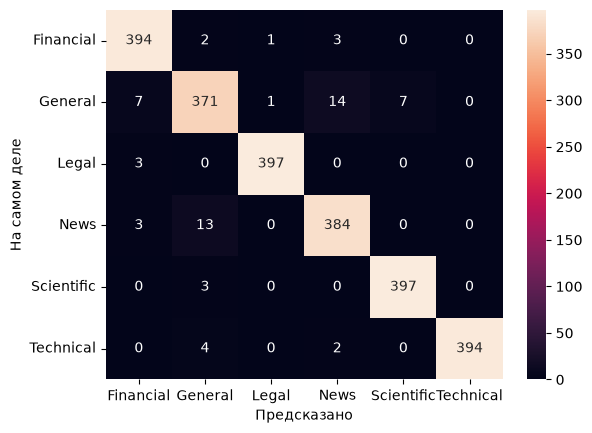

In [32]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

cn = confusion_matrix(output.label_ids,y_pred)



sns.heatmap(
    cn,
    annot=True,  # писать числа внутри клеток
    fmt="d",  # показывать целые числа
    xticklabels=labels,  # подписи столбцов
    yticklabels=labels,  # подписи строк
)

plt.xlabel("Предсказано")
plt.ylabel("На самом деле")
plt.show()

## 13. Вывод: DistilBERT против baseline

| Модель | Accuracy | Macro-F1 | Ошибок из 2400 | Время обучения |
|---|---|---|---|---|
| Baseline: TF-IDF + логистическая регрессия | 0,942 | 0,942 | 139 | секунды (CPU) |
| **DistilBERT (дообучение, 3 эпохи)** | **0,9738** | **0,9737** | **63** | около 10 мин 7 с (GPU) |

Обе модели проверены на **одном и том же** тесте из 2400 текстов. Сохранённая версия DistilBERT сделала 63 ошибки вместо 139 у baseline и превзошла целевые показатели из записки (accuracy ≥ 0,85, macro-F1 ≥ 0,82). Предыдущий запуск дал 58 ошибок: разница в пять текстов мала и сама по себе не требует переобучения.

**Качество по классам (F1):**

| Класс | Baseline | DistilBERT |
|---|---|---|
| Legal | 0,985 | **0,994** |
| Technical | 0,968 | **0,992** |
| Scientific | 0,975 | **0,988** |
| Financial | 0,959 | **0,976** |
| News | 0,891 | **0,956** |
| General | 0,874 | **0,936** |

DistilBERT лучше **по всем шести классам**. Например, recall News вырос с 0,845 до 0,960: модель стала узнавать больше новостей среди настоящих новостей.

**Некоторые ошибки по матрицам ошибок:**

| Ошибка | Baseline | DistilBERT |
|---|---|---|
| News → General | 44 | 13 |
| General → News | 18 | 14 |
| News → Technical | 10 | 0 |
| General → Scientific | 10 | 7 |
| Financial → General | 8 | 2 |

Чаще всего остаётся путаница между News и General: 13 новостей классифицированы как General, а 14 текстов General --- как News. Модель должна различать жанр этих текстов, хотя темы могут совпадать.

**Почему DistilBERT может помочь.** TF-IDF учитывает частоты слов и словосочетаний, а DistilBERT использует их окружение и порядок. Это помогает различать похожие по словарю тексты разных жанров.

**Цена улучшения:** модель существенно больше baseline (около 255 МБ против 3 МБ); обучение и предсказание требуют больше времени и памяти. В приложении документ планируется классифицировать один раз при загрузке, а результат сохранять.

## 14. Сохранение модели и проверка загрузки

`trainer.save_model(...)` сохраняет дообученную модель вместе с токенизатором в папку `models/distilbert_doc_classifier/`. Это отдельная папка для использования модели после обучения; `models/distilbert_checkpoints/` содержит промежуточные снимки обучения.

`trainer.save_metrics("test", output.metrics)` сохраняет показатели теста в `models/distilbert_checkpoints/test_results.json`. Здесь `"test"` --- имя набора данных, а не путь к папке. Путь уже задан в `TrainingArguments(output_dir=...)`.

Следующая ячейка создаёт `pipeline` и загружает **сохранённую модель с диска**. Последняя ячейка проверяет её на трёх коротких примерах. `label` --- предсказанный тип документа; `score` --- уверенность модели для выбранного класса. Эти три примера показывают, что загрузка и предсказание работают. Общую точность оцениваем по тесту из 2400 текстов выше, а не по ним.

In [33]:
trainer.save_model("../../models/distilbert_doc_classifier")
trainer.save_metrics("test", output.metrics)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

In [34]:
from transformers import pipeline

classifier = pipeline(
    "text-classification",
    model="../../models/distilbert_doc_classifier"
)

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

In [35]:
print(classifier("The Borrower shall repay the loan in full on the maturity date.")  
)
print(classifier("Police said the suspect was arrested on Tuesday, officials told reporters.")
)
print(classifier("I installed Ubuntu but my wifi driver does not work, how can I fix it?"))

[{'label': 'Legal', 'score': 0.9984245300292969}]
[{'label': 'News', 'score': 0.9982013702392578}]
[{'label': 'Technical', 'score': 0.9984539747238159}]
